In [1]:
import xgboost as xgb
import pandas as pd
import seaborn as sns
import logging
import time
import matplotlib.pyplot as plt
import talib as ta
import numpy as np
import optuna

from sklearn.feature_selection import VarianceThreshold, RFECV
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR

from typing import Tuple
from pathlib import Path

from config.settings import ROOT_DIR

DATA_RAW_DIR = ROOT_DIR / "data" / "raw"
DATA_PROC_DIR = ROOT_DIR / "data" / "processed"
SBERBANK_CSV = DATA_RAW_DIR / "sberbank_stock_prices.csv"
GOLD_TIME_SERIES_CSV = DATA_RAW_DIR / "gold_time_series.csv"
OIL_BRENT_TIME_SERIES_CSV = DATA_RAW_DIR / "oil_brent_time_series.csv"
USD_RUB_TIME_SERIES_CSV = DATA_RAW_DIR / "usd_rub_time_series.csv"
CB_RATE_CSV = DATA_RAW_DIR / "cb_rate.csv"

optuna.logging.set_verbosity(optuna.logging.WARNING)

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    handlers=[
        logging.StreamHandler()
    ]
)
logger = logging.getLogger(__name__)

In [34]:
def plot_gap_filling(df_original: pd.DataFrame, df_filled: pd.DataFrame,
                      start_date: str, end_date: str,
                      save_path: str = None):
    """
    Строит два подграфика:
    - исходный ряд (только торговые дни) в виде маркеров;
    - ряд после заполнения (сплошная линия) с выделением добавленных точек.
    """
    # Выделяем фрагмент
    orig_frag = df_original.loc[start_date:end_date].copy()
    filled_frag = df_filled.loc[start_date:end_date].copy()

    # Определяем добавленные дни: те, которые есть в filled, но отсутствуют в orig
    added_days = filled_frag.index.difference(orig_frag.index)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # (а) Исходный ряд – только маркеры
    axes[0].plot(orig_frag.index, orig_frag['Close'], 'bo', markersize=4, label='Торговые дни')
    axes[0].set_title('а) Только торговые дни')
    axes[0].set_xlabel('Дата')
    axes[0].set_ylabel('Цена закрытия')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.5)

    # (б) После заполнения – линия + добавленные дни красным
    axes[1].plot(filled_frag.index, filled_frag['Close'], 'b-', linewidth=1, label='После forward fill')
    # Отмечаем добавленные дни красными кружками
    if len(added_days) > 0:
        axes[1].plot(added_days, filled_frag.loc[added_days, 'Close'], 'ro', markersize=5, label='Добавленные дни')
    axes[1].set_title('б) После forward fill')
    axes[1].set_xlabel('Дата')
    axes[1].set_ylabel('Цена закрытия')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

In [2]:
def euro_to_float(x):
    if pd.isna(x):
        return x
    if isinstance(x, (int, float)):
        return float(x)
    try:
        cleaned = str(x).replace('.', '').replace(',', '.')
        return float(cleaned)
    except (ValueError, AttributeError):
        return x  # если не удалось преобразовать, оставляем исходное

In [3]:
def forward_fill_to_date(df: pd.DataFrame, end_date) -> pd.DataFrame:
    df = df.sort_index()
    start_date = df.index.min()
    end_date = pd.to_datetime(end_date)

    if end_date < start_date:
        raise ValueError("end_date должна быть не меньше минимальной даты в индексе")

    full_range = pd.date_range(start=start_date, end=end_date, freq='D')

    df_filled = df.reindex(full_range).ffill()

    return df_filled

In [21]:
def load_sberbank() -> pd.DataFrame:
    df = pd.read_csv(SBERBANK_CSV, delimiter=';', dtype={'<DATE>' : str})
    name_map = {column:column[1:-1].capitalize() for column in df.columns.tolist()}
    df = df.rename(columns=name_map)
    df['Date'] = pd.to_datetime(df['Date'], format='%y%m%d')
    df.set_index('Date', inplace=True)
    return df

In [5]:
def get_key_rate() -> pd.DataFrame:
    df_rate = pd.read_csv(CB_RATE_CSV, parse_dates=['Дата'])
    df_rate = df_rate.set_index('Дата')
    df_rate.index = pd.to_datetime(df_rate.index)
    df_rate.rename(columns={'Ставка': 'Rate'}, inplace=True)
    df_rate = forward_fill_to_date(df_rate, '09.01.2025')
    return df_rate

In [6]:
def get_time_series(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, delimiter=';')
    df = df.set_index('Date')
    df.index = pd.to_datetime(df.index, dayfirst=True)
    for col in df.select_dtypes(include=['object']).columns:
        df[col] = pd.to_numeric(df[col].apply(euro_to_float), errors='coerce')
    df = forward_fill_to_date(df, '09.01.2025')
    return df

In [7]:
def create_lags(df: pd.DataFrame, column: str, n_lags: int) -> pd.DataFrame:
    new_df = df.copy()
    for lag in range(1, n_lags + 1):
        new_df[f'{column}_lag_{lag}'] = new_df[column].shift(lag)

    return new_df

In [84]:
def generate_features_for_factor(
    df: pd.DataFrame,
    n_lags: int,
    sma_period: int,
    ema_period: int,
    rsi_period: int,
    stoch_fastk: int,
    stoch_slowd: int,
    macd_fast: int,
    macd_slow: int,
    macd_signal: int,
    roc_period: int,
    vol_window: int,
    target_col: str = 'Close'
) -> pd.DataFrame:
    """
    Генерирует признаки для одного фактора на основе цен OHLC.
    Возвращает X (признаки) с индексом, соответствующим дате расчёта.
    Признаки рассчитываются по данным этого же дня (без сдвига).
    """
    df = df.copy()
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)

    close = df[target_col]
    high = df['High'] if 'High' in df.columns else close
    low = df['Low'] if 'Low' in df.columns else close
    open_ = df['Open'] if 'Open' in df.columns else close

    X = pd.DataFrame(index=df.index)

    # 1. Лаги
    for lag in range(1, n_lags + 1):
        X[f'close_lag_{lag}'] = close.shift(lag)

    # 2. Внутридневные (используются данные текущего дня)
    X['high_low'] = high - low
    X['close_open'] = close - open_
    # защита от деления на ноль
    with np.errstate(divide='ignore', invalid='ignore'):
        X['high_low_norm'] = (high - low) / close

    # 3. Доходности
    X['return_1'] = close.pct_change()
    # логарифмическая доходность: нужно избегать zero/negative
    log_return = np.log(close / close.shift(1))
    X['log_return_1'] = log_return

    # 4. Скользящие средние
    X['SMA'] = ta.SMA(close, timeperiod=sma_period)
    X['EMA'] = ta.EMA(close, timeperiod=ema_period)
    X['SMA_EMA_diff'] = X['EMA'] - X['SMA']

    # 5. MACD
    macd, macd_signal_line, macd_hist = ta.MACD(
        close, fastperiod=macd_fast, slowperiod=macd_slow, signalperiod=macd_signal
    )
    X['MACD'] = macd
    X['MACD_signal'] = macd_signal_line
    X['MACD_hist'] = macd_hist

    # 6. RSI
    X['RSI'] = ta.RSI(close, timeperiod=rsi_period)

    # 7. Стохастик
    slowk, slowd = ta.STOCH(
        high, low, close,
        fastk_period=stoch_fastk,
        slowk_period=3,
        slowk_matype=0,
        slowd_period=stoch_slowd,
        slowd_matype=0
    )
    X['STOCH_K'] = slowk
    X['STOCH_D'] = slowd

    # 8. Волатильность
    X['Std'] = close.rolling(vol_window).std()
    X['ATR'] = ta.ATR(high, low, close, timeperiod=vol_window)
    upper, middle, lower = ta.BBANDS(close, timeperiod=vol_window)
    with np.errstate(divide='ignore', invalid='ignore'):
        X['BB_width'] = (upper - lower) / middle
        X['BB_position'] = (close - lower) / (upper - lower)

    # 9. ROC
    X['ROC'] = ta.ROC(close, timeperiod=roc_period)

    # Замена бесконечностей на NaN и удаление строк с NaN
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.dropna()
    return X

In [93]:
def optimize_factor(
    df_factor: pd.DataFrame,
    target_df: pd.DataFrame,
    factor_name: str,
    target_col: str = 'Close',
    n_trials: int = 100,
    n_splits: int = 5
):
    """
    Оптимизирует параметры индикаторов для фактора factor_name.
    Признаки строятся из df_factor, целевая переменная — target_col из target_df (цена закрытия).
    Для прогноза используется принцип: признаки на день t-1 предсказывают цену на день t.
    """
    logger.info(f"Начало оптимизации для фактора {factor_name}")
    
    # Общие даты
    common_dates = df_factor.index.intersection(target_df.index)
    df_factor = df_factor.loc[common_dates]
    target_df = target_df.loc[common_dates]
    logger.info(f"Общих дат: {len(common_dates)}")

    # Целевая переменная: цена закрытия Сбербанка на текущий день
    y_target = target_df[target_col]

    def objective(trial):
        # Параметры
        params = {
            'n_lags': trial.suggest_int('n_lags', 1, 6),
            'sma_period': trial.suggest_int('sma_period', 5, 14),
            'ema_period': trial.suggest_int('ema_period', 5, 14),
            'rsi_period': trial.suggest_int('rsi_period', 5, 20),
            'stoch_fastk': trial.suggest_int('stoch_fastk', 5, 20),
            'stoch_slowd': trial.suggest_int('stoch_slowd', 3, 10),
            'macd_fast': trial.suggest_int('macd_fast', 8, 20),
            'macd_slow': trial.suggest_int('macd_slow', 20, 30),
            'macd_signal': trial.suggest_int('macd_signal', 5, 15),
            'roc_period': trial.suggest_int('roc_period', 3, 15),
            'vol_window': trial.suggest_int('vol_window', 5, 15)
        }

        # Генерируем признаки из фактора (признаки соответствуют дате t)
        X = generate_features_for_factor(
            df=df_factor,
            target_col=target_col,
            **params
        )
        # Сдвигаем признаки на 1 день вперёд: для даты t получаем признаки, рассчитанные на t-1
        X_shifted = X.shift(1)

        # Объединяем с целевой переменной по индексу, удаляем NaN
        combined = pd.concat([X_shifted, y_target], axis=1).dropna()
        if combined.shape[0] < 50:
            return 1.0

        X_clean = combined.iloc[:, :-1]
        y_clean = combined.iloc[:, -1]

        # Временная кросс-валидация
        tscv = TimeSeriesSplit(n_splits=n_splits)
        model = GradientBoostingRegressor(random_state=42, n_estimators=50)
        mape_scores = []

        for fold, (train_idx, test_idx) in enumerate(tscv.split(X_clean), 1):
            X_train, X_test = X_clean.iloc[train_idx], X_clean.iloc[test_idx]
            y_train, y_test = y_clean.iloc[train_idx], y_clean.iloc[test_idx]

            if len(y_train) < 10 or len(y_test) < 10:
                continue

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            mape = mean_absolute_percentage_error(y_test, y_pred)
            mape_scores.append(mape)

        if not mape_scores:
            return 1.0
        mean_mape = np.mean(mape_scores)
        logger.debug(f"Trial {trial.number}: MAPE = {mean_mape:.4f}")
        return mean_mape

    study = optuna.create_study(direction='minimize', study_name=factor_name)
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

    logger.info(f"Оптимизация для {factor_name} завершена")
    logger.info(f"Лучшее значение MAPE: {study.best_value:.4f}")
    logger.info("Лучшие параметры:")
    for k, v in study.best_params.items():
        logger.info(f"  {k}: {v}")

    return study.best_params

In [94]:
TARGET_COLUMN = 'Close'

stock_data = load_sberbank()
sber_df = forward_fill_to_date(stock_data, '09.01.2025')
gold_df = get_time_series(GOLD_TIME_SERIES_CSV)
oil_df = get_time_series(OIL_BRENT_TIME_SERIES_CSV)
usd_rub_df = get_time_series(USD_RUB_TIME_SERIES_CSV)

best_sber = optimize_factor(sber_df, sber_df, 'SBER', target_col=TARGET_COLUMN, n_trials=50)
best_gold = optimize_factor(gold_df, sber_df, 'GOLD', target_col=TARGET_COLUMN, n_trials=50)
best_oil = optimize_factor(oil_df, sber_df, 'OIL', target_col=TARGET_COLUMN, n_trials=50)
best_usdrub = optimize_factor(usd_rub_df, sber_df, 'USDRUB', target_col=TARGET_COLUMN, n_trials=50)

# Сводная таблица
results = pd.DataFrame(
    [best_sber, best_gold, best_oil, best_usdrub],
    index=['SBER', 'GOLD', 'OIL', 'USDRUB']
)
print("\nСводная таблица оптимальных параметров:")
print(results)

2026-03-02 20:08:40,569 - INFO - Начало оптимизации для фактора SBER
2026-03-02 20:08:40,572 - INFO - Общих дат: 1827


  0%|          | 0/50 [00:00<?, ?it/s]

2026-03-02 20:10:02,075 - INFO - Оптимизация для SBER завершена
2026-03-02 20:10:02,077 - INFO - Лучшее значение MAPE: 0.0587
2026-03-02 20:10:02,079 - INFO - Лучшие параметры:
2026-03-02 20:10:02,080 - INFO -   n_lags: 2
2026-03-02 20:10:02,082 - INFO -   sma_period: 11
2026-03-02 20:10:02,085 - INFO -   ema_period: 13
2026-03-02 20:10:02,087 - INFO -   rsi_period: 18
2026-03-02 20:10:02,088 - INFO -   stoch_fastk: 17
2026-03-02 20:10:02,090 - INFO -   stoch_slowd: 7
2026-03-02 20:10:02,091 - INFO -   macd_fast: 17
2026-03-02 20:10:02,091 - INFO -   macd_slow: 25
2026-03-02 20:10:02,092 - INFO -   macd_signal: 5
2026-03-02 20:10:02,094 - INFO -   roc_period: 6
2026-03-02 20:10:02,094 - INFO -   vol_window: 5
2026-03-02 20:10:02,096 - INFO - Начало оптимизации для фактора GOLD
2026-03-02 20:10:02,101 - INFO - Общих дат: 1827


  0%|          | 0/50 [00:00<?, ?it/s]

2026-03-02 20:11:19,331 - INFO - Оптимизация для GOLD завершена
2026-03-02 20:11:19,333 - INFO - Лучшее значение MAPE: 0.4228
2026-03-02 20:11:19,334 - INFO - Лучшие параметры:
2026-03-02 20:11:19,335 - INFO -   n_lags: 1
2026-03-02 20:11:19,336 - INFO -   sma_period: 13
2026-03-02 20:11:19,337 - INFO -   ema_period: 6
2026-03-02 20:11:19,340 - INFO -   rsi_period: 12
2026-03-02 20:11:19,341 - INFO -   stoch_fastk: 7
2026-03-02 20:11:19,341 - INFO -   stoch_slowd: 3
2026-03-02 20:11:19,342 - INFO -   macd_fast: 14
2026-03-02 20:11:19,343 - INFO -   macd_slow: 21
2026-03-02 20:11:19,345 - INFO -   macd_signal: 15
2026-03-02 20:11:19,346 - INFO -   roc_period: 14
2026-03-02 20:11:19,348 - INFO -   vol_window: 14
2026-03-02 20:11:19,349 - INFO - Начало оптимизации для фактора OIL
2026-03-02 20:11:19,354 - INFO - Общих дат: 1827


  0%|          | 0/50 [00:00<?, ?it/s]

2026-03-02 20:12:48,296 - INFO - Оптимизация для OIL завершена
2026-03-02 20:12:48,298 - INFO - Лучшее значение MAPE: 0.2950
2026-03-02 20:12:48,299 - INFO - Лучшие параметры:
2026-03-02 20:12:48,300 - INFO -   n_lags: 6
2026-03-02 20:12:48,302 - INFO -   sma_period: 7
2026-03-02 20:12:48,303 - INFO -   ema_period: 9
2026-03-02 20:12:48,305 - INFO -   rsi_period: 9
2026-03-02 20:12:48,306 - INFO -   stoch_fastk: 18
2026-03-02 20:12:48,307 - INFO -   stoch_slowd: 7
2026-03-02 20:12:48,309 - INFO -   macd_fast: 19
2026-03-02 20:12:48,310 - INFO -   macd_slow: 28
2026-03-02 20:12:48,311 - INFO -   macd_signal: 5
2026-03-02 20:12:48,312 - INFO -   roc_period: 13
2026-03-02 20:12:48,312 - INFO -   vol_window: 14
2026-03-02 20:12:48,315 - INFO - Начало оптимизации для фактора USDRUB
2026-03-02 20:12:48,319 - INFO - Общих дат: 1827


  0%|          | 0/50 [00:00<?, ?it/s]

2026-03-02 20:14:08,938 - INFO - Оптимизация для USDRUB завершена
2026-03-02 20:14:08,939 - INFO - Лучшее значение MAPE: 0.2066
2026-03-02 20:14:08,941 - INFO - Лучшие параметры:
2026-03-02 20:14:08,943 - INFO -   n_lags: 3
2026-03-02 20:14:08,944 - INFO -   sma_period: 11
2026-03-02 20:14:08,945 - INFO -   ema_period: 13
2026-03-02 20:14:08,946 - INFO -   rsi_period: 15
2026-03-02 20:14:08,947 - INFO -   stoch_fastk: 5
2026-03-02 20:14:08,949 - INFO -   stoch_slowd: 7
2026-03-02 20:14:08,949 - INFO -   macd_fast: 9
2026-03-02 20:14:08,950 - INFO -   macd_slow: 29
2026-03-02 20:14:08,952 - INFO -   macd_signal: 9
2026-03-02 20:14:08,953 - INFO -   roc_period: 8
2026-03-02 20:14:08,953 - INFO -   vol_window: 7



Сводная таблица оптимальных параметров:
        n_lags  sma_period  ema_period  rsi_period  stoch_fastk  stoch_slowd  \
SBER         2          11          13          18           17            7   
GOLD         1          13           6          12            7            3   
OIL          6           7           9           9           18            7   
USDRUB       3          11          13          15            5            7   

        macd_fast  macd_slow  macd_signal  roc_period  vol_window  
SBER           17         25            5           6           5  
GOLD           14         21           15          14          14  
OIL            19         28            5          13          14  
USDRUB          9         29            9           8           7  


In [ ]:
def generate_external_features(
    ext_df: pd.DataFrame,
    name_prefix: str,
    n_lags: int = 3,
    ema_period: int = 9,
    rsi_period: int = 9,
    rolling_window: int = 11,
    include_volatility: bool = True,
    include_oscillators: bool = True,
) -> pd.DataFrame:
    """
    Генерирует расширенный набор признаков для одного внешнего фактора
    (например, золото, нефть, доллар, ставка).

    Параметры
    ----------
    ext_df : pd.DataFrame
        Исходный DataFrame внешнего фактора, должен содержать колонки
        'Open', 'High', 'Low', 'Close' (может отсутствовать часть, но тогда
        некоторые индикаторы не будут рассчитаны).
    name_prefix : str
        Префикс для названий колонок (например, 'Gold', 'Oil').
    n_lags : int
        Количество лагов цены закрытия.
    ema_period : int
        Период для EMA.
    rsi_period : int
        Период для RSI.
    rolling_window : int
        Окно для скользящих расчётов (SMA, Std, ATR и т.д.).
    include_volatility : bool
        Включать ли индикаторы волатильности (ATR, полосы Боллинджера).
    include_oscillators : bool
        Включать ли осцилляторы (RSI, Stochastic).

    Возвращает
    -------
    pd.DataFrame
        Датафрейм с признаками, индексированный по датам (даты те же, что и в ext_df).
        Значения признаков на дату t рассчитаны по данным до t включительно.
        **Внимание:** перед объединением с основным рядом этот датафрейм нужно
        сдвинуть на 1 шаг (shift(1)), чтобы избежать утечки будущего.
    """
    df = ext_df.copy()

    close = df['Close']
    high = df['High'] if 'High' in df.columns else None
    low = df['Low'] if 'Low' in df.columns else None
    open = df['Open'] if 'Open' in df.columns else None

    out = pd.DataFrame(index=df.index)

    for k in range(1, n_lags + 1):
        out[f"{name_prefix}_lag_{k}"] = close.shift(k)

    out[f"{name_prefix}_Open_lag_1"] = open.shift(1)
    out[f"{name_prefix}_High_lag_1"] = high.shift(1)
    out[f"{name_prefix}_Low_lag_1"] = low.shift(1)

    out[f"{name_prefix}_return_1"] = close.pct_change()
    out[f"{name_prefix}_log_return_1"] = np.log(close / close.shift(1))

    out[f"{name_prefix}_return_5"] = close.pct_change(periods=5)
    out[f"{name_prefix}_log_return_5"] = np.log(close / close.shift(5))

    out[f"{name_prefix}_EMA_{ema_period}"] = ta.EMA(close, timeperiod=ema_period)
    out[f"{name_prefix}_SMA_{rolling_window}"] = ta.SMA(close, timeperiod=rolling_window)
    out[f"{name_prefix}_EMA_SMA_diff"] = out[f"{name_prefix}_EMA_{ema_period}"] - out[f"{name_prefix}_SMA_{rolling_window}"]

    macd, macd_signal, macd_hist = ta.MACD(close, fastperiod=12, slowperiod=26, signalperiod=9)
    out[f"{name_prefix}_MACD"] = macd
    out[f"{name_prefix}_MACD_signal"] = macd_signal
    out[f"{name_prefix}_MACD_hist"] = macd_hist

    out[f"{name_prefix}_RSI_{rsi_period}"] = ta.RSI(close, timeperiod=rsi_period)
    out[f"{name_prefix}_ROC_5"] = ta.ROC(close, timeperiod=5)
    out[f"{name_prefix}_Stoch_K"], out[f"{name_prefix}_Stoch_D"] = ta.STOCH(high, low, close)

    out[f"{name_prefix}_Std_{rolling_window}"] = close.rolling(rolling_window).std()
    out[f"{name_prefix}_ATR"] = ta.ATR(high, low, close, timeperiod=rolling_window)
    upper, middle, lower = ta.BBANDS(close, timeperiod=rolling_window)
    out[f"{name_prefix}_BB_width"] = (upper - lower) / middle
    out[f"{name_prefix}_BB_position"] = (close - lower) / (upper - lower)


    out[f"{name_prefix}_intraday_range"] = high - low
    out[f"{name_prefix}_intraday_return"] = close - open
    out[f"{name_prefix}_relative_range"] = (high - low) / close if high is not None and low is not None else np.nan

    out.dropna(inplace=True)

    return out

In [68]:
def create_ta_features(
    df: pd.DataFrame,
    n_lags: int = 4,
    ema_period: int = 9,
    rsi_period: int = 9,
    rolling_window: int = 11,
    target: str = "Close",
    external_config = None
) -> pd.DataFrame:
    """
    Основная функция генерации признаков, включая внешние факторы.

    Параметры
    ----------
    external_config : list of dict, optional
        Список конфигураций для внешних факторов. Каждый словарь должен содержать:
            - 'name': префикс для признаков (например, 'Gold')
            - 'df_features': pd.DataFrame с колонками (минимум Close)
            - 'n_lags', 'ema_period', ... (опционально, переопределяют глобальные)
        Если None, используются только внутренние признаки.
    """
    logger.info("=" * 60)
    logger.info("НАЧАЛО ГЕНЕРАЦИИ ПРИЗНАКОВ")
    logger.info("=" * 60)

    out = df.copy()
    initial_rows = len(out)
    initial_cols = out.shape[1]
    logger.info(f"Исходный датафрейм: строк = {initial_rows}, колонок = {initial_cols}")

    # Удаляем служебные колонки, если они есть
    cols_to_drop = ['Ticker', 'Per', 'Time']
    existing_drop = [c for c in cols_to_drop if c in out.columns]
    if existing_drop:
        out.drop(columns=existing_drop, inplace=True)
        logger.info(f"Удалены служебные колонки: {existing_drop}")

    # =========================
    # 1. ВНЕШНИЕ ФАКТОРЫ (расширенные)
    # =========================
    rate_df = get_key_rate().shift(1)
    out['Rate_change'] = rate_df.pct_change()
    
    
    if external_config is not None:
        logger.info("--- Этап 1: Внешние факторы ---")
        for idx, cfg in enumerate(external_config, 1):
            name = cfg['name']
            ext_data = cfg['data'].copy()
            logger.info(f"  Обработка внешнего фактора {idx}: {name}")

            # Параметры для конкретного фактора
            ext_n_lags = cfg.get('n_lags', n_lags)
            ext_ema = cfg.get('ema_period', ema_period)
            ext_rsi = cfg.get('rsi_period', rsi_period)
            ext_win = cfg.get('rolling_window', rolling_window)

            # Генерируем признаки на полной истории внешнего фактора
            ext_features = generate_external_features(
                ext_df=ext_data,
                name_prefix=name,
                n_lags=ext_n_lags,
                ema_period=ext_ema,
                rsi_period=ext_rsi,
                rolling_window=ext_win,
                include_volatility=True,
                include_oscillators=True
            )

            # Сдвигаем на 1 день, чтобы использовать только вчерашние данные
            ext_features_shifted = ext_features.shift(1)
            n_new_features = ext_features_shifted.shape[1]
            logger.info(f"    Сгенерировано {n_new_features} признаков для {name}")

            # Объединяем с основным датафреймом по индексу
            before_join = out.shape[1]
            out = out.join(ext_features_shifted, how='left')
            after_join = out.shape[1]
            logger.info(f"    Добавлено {after_join - before_join} признаков (всего теперь {after_join})")

            # Проверим, не появились ли полностью пустые колонки
            empty_cols = out.columns[out.isnull().all()].tolist()
            if empty_cols:
                logger.warning(f"    Колонки полностью пусты после join: {empty_cols}")

    # =========================
    # 2. ЛАГОВЫЕ ПРИЗНАКИ (акции)
    # =========================
    logger.info("--- Этап 2: Лаговые признаки (акции) ---")
    before_lags = out.shape[1]
    for k in range(1, n_lags + 1):
        out[f"{target}_lag_{k}"] = out[target].shift(k)

    out["Open_lag_1"]  = out["Open"].shift(1)
    out["High_lag_1"]  = out["High"].shift(1)
    out["Low_lag_1"]   = out["Low"].shift(1)
    after_lags = out.shape[1]
    logger.info(f"  Добавлено лаговых признаков: {after_lags - before_lags} (всего {after_lags})")

    c1 = out[f"{target}_lag_1"]
    h1 = out["High_lag_1"]
    l1 = out["Low_lag_1"]
    o1 = out["Open_lag_1"]

    # =========================
    # 3. ДОХОДНОСТИ (акции)
    # =========================
    logger.info("--- Этап 3: Доходности (акции) ---")
    before_ret = out.shape[1]
    out["Log_return_1"] = np.log(c1 / out[f"{target}_lag_2"])
    out["Return_1"]     = c1.pct_change()
    after_ret = out.shape[1]
    logger.info(f"  Добавлено признаков доходности: {after_ret - before_ret} (всего {after_ret})")

    # =========================
    # 4. ТРЕНДОВЫЕ ИНДИКАТОРЫ (акции)
    # =========================
    logger.info("--- Этап 4: Трендовые индикаторы (акции) ---")
    before_trend = out.shape[1]
    out[f"EMA_{ema_period}"] = ta.EMA(c1, timeperiod=ema_period)
    out[f"SMA_{rolling_window}"] = ta.SMA(c1, timeperiod=rolling_window)
    out["EMA_SMA_diff"] = out[f"EMA_{ema_period}"] - out[f"SMA_{rolling_window}"]
    macd, macd_signal, macd_hist = ta.MACD(c1, fastperiod=12, slowperiod=26, signalperiod=9)
    out["MACD"] = macd
    out["MACD_signal"] = macd_signal
    out["MACD_hist"] = macd_hist
    after_trend = out.shape[1]
    logger.info(f"  Добавлено трендовых индикаторов: {after_trend - before_trend} (всего {after_trend})")

    # =========================
    # 5. ОСЦИЛЛЯТОРЫ (акции)
    # =========================
    logger.info("--- Этап 5: Осцилляторы (акции) ---")
    before_osc = out.shape[1]
    out[f"RSI_{rsi_period}"] = ta.RSI(c1, timeperiod=rsi_period)
    out["ROC_5"] = ta.ROC(c1, timeperiod=5)
    out["Stoch_K"], out["Stoch_D"] = ta.STOCH(h1, l1, c1)
    after_osc = out.shape[1]
    logger.info(f"  Добавлено осцилляторов: {after_osc - before_osc} (всего {after_osc})")

    # =========================
    # 6. ВОЛАТИЛЬНОСТЬ (акции)
    # =========================
    logger.info("--- Этап 6: Волатильность (акции) ---")
    before_vol = out.shape[1]
    out[f"Std_{rolling_window}"] = c1.rolling(rolling_window).std()
    out["ATR"] = ta.ATR(h1, l1, c1, timeperiod=rolling_window)
    upper, middle, lower = ta.BBANDS(c1, timeperiod=rolling_window)
    out["BB_width"] = (upper - lower) / middle
    out["BB_position"] = (c1 - lower) / (upper - lower)
    after_vol = out.shape[1]
    logger.info(f"  Добавлено индикаторов волатильности: {after_vol - before_vol} (всего {after_vol})")

    # =========================
    # 7. ВНУТРИДНЕВНЫЕ ХАРАКТЕРИСТИКИ (акции)
    # =========================
    logger.info("--- Этап 7: Внутридневные характеристики (акции) ---")
    before_intra = out.shape[1]
    out["Intraday_range"] = h1 - l1
    out["Intraday_return"] = c1 - o1
    out["Relative_range"] = (h1 - l1) / c1
    after_intra = out.shape[1]
    logger.info(f"  Добавлено внутридневных признаков: {after_intra - before_intra} (всего {after_intra})")

    # =========================
    # 8. УДАЛЕНИЕ ЛИШНЕГО
    # =========================
    logger.info("--- Этап 8: Очистка ---")
    # Удаляем исходные колонки Open/High/Low, так как они больше не нужны
    cols_to_drop_final = ["Open", "High", "Low"]
    existing_final = [c for c in cols_to_drop_final if c in out.columns]
    if existing_final:
        out.drop(columns=existing_final, inplace=True)
        logger.info(f"  Удалены исходные ценовые колонки: {existing_final}")

    # Удаляем строки с пропусками (первые дни, где не хватает лагов)
    before_dropna = len(out)
    out.dropna(inplace=True)
    after_dropna = len(out)
    dropped_rows = before_dropna - after_dropna
    logger.info(f"  Удалено строк с пропусками: {dropped_rows} (осталось {after_dropna})")

    # Итоговая статистика
    logger.info("=" * 60)
    logger.info("ИТОГ ГЕНЕРАЦИИ ПРИЗНАКОВ")
    logger.info(f"  Итоговое количество признаков: {out.shape[1]}")
    logger.info(f"  Итоговое количество строк: {out.shape[0]}")
    logger.info("=" * 60)

    return out

In [69]:
TARGET_COLUMN = 'Close'

stock_data = load_sberbank()
forward_fill_stock_data = forward_fill_to_date(stock_data, '09.01.2025')
gold_df = get_time_series(GOLD_TIME_SERIES_CSV)
oil_df = get_time_series(OIL_BRENT_TIME_SERIES_CSV)
usd_rub_df = get_time_series(USD_RUB_TIME_SERIES_CSV)

# Конфигурация внешних факторов
external_config = [
    {'name': 'Gold', 'data': gold_df, 'n_lags': 3, 'rolling_window': 10},
    {'name': 'Oil', 'data': oil_df, 'n_lags': 3, 'rolling_window': 10},
    {'name': 'USDRUB', 'data': usd_rub_df, 'n_lags': 3, 'rolling_window': 10},
]

# Генерируем полный набор признаков
df_features = create_ta_features(
    df=forward_fill_stock_data,
    n_lags=4,
    ema_period=9,
    rsi_period=9,
    rolling_window=11,
    target='Close',
    external_config=external_config
)

2026-03-02 16:42:11,209 - INFO - ============================================================
2026-03-02 16:42:11,213 - INFO - НАЧАЛО ГЕНЕРАЦИИ ПРИЗНАКОВ
2026-03-02 16:42:11,217 - INFO - ============================================================
2026-03-02 16:42:11,219 - INFO - Исходный датафрейм: строк = 1827, колонок = 7
2026-03-02 16:42:11,224 - INFO - Удалены служебные колонки: ['Ticker', 'Per', 'Time']
2026-03-02 16:42:11,252 - INFO - --- Этап 1: Внешние факторы ---
2026-03-02 16:42:11,256 - INFO -   Обработка внешнего фактора 1: Gold
2026-03-02 16:42:11,311 - INFO -     Сгенерировано 27 признаков для Gold
2026-03-02 16:42:11,323 - INFO -     Добавлено 27 признаков (всего теперь 32)
2026-03-02 16:42:11,328 - INFO -   Обработка внешнего фактора 2: Oil
2026-03-02 16:42:11,361 - INFO -     Сгенерировано 27 признаков для Oil
2026-03-02 16:42:11,384 - INFO -     Добавлено 27 признаков (всего теперь 59)
2026-03-02 16:42:11,391 - INFO -   Обработка внешнего фактора 3: USDRUB
2026-03-02

In [70]:
df_features.columns.to_list()

['Close',
 'Rate_change',
 'Gold_lag_1',
 'Gold_lag_2',
 'Gold_lag_3',
 'Gold_Open_lag_1',
 'Gold_High_lag_1',
 'Gold_Low_lag_1',
 'Gold_return_1',
 'Gold_log_return_1',
 'Gold_return_5',
 'Gold_log_return_5',
 'Gold_EMA_9',
 'Gold_SMA_10',
 'Gold_EMA_SMA_diff',
 'Gold_MACD',
 'Gold_MACD_signal',
 'Gold_MACD_hist',
 'Gold_RSI_9',
 'Gold_ROC_5',
 'Gold_Stoch_K',
 'Gold_Stoch_D',
 'Gold_Std_10',
 'Gold_ATR',
 'Gold_BB_width',
 'Gold_BB_position',
 'Gold_intraday_range',
 'Gold_intraday_return',
 'Gold_relative_range',
 'Oil_lag_1',
 'Oil_lag_2',
 'Oil_lag_3',
 'Oil_Open_lag_1',
 'Oil_High_lag_1',
 'Oil_Low_lag_1',
 'Oil_return_1',
 'Oil_log_return_1',
 'Oil_return_5',
 'Oil_log_return_5',
 'Oil_EMA_9',
 'Oil_SMA_10',
 'Oil_EMA_SMA_diff',
 'Oil_MACD',
 'Oil_MACD_signal',
 'Oil_MACD_hist',
 'Oil_RSI_9',
 'Oil_ROC_5',
 'Oil_Stoch_K',
 'Oil_Stoch_D',
 'Oil_Std_10',
 'Oil_ATR',
 'Oil_BB_width',
 'Oil_BB_position',
 'Oil_intraday_range',
 'Oil_intraday_return',
 'Oil_relative_range',
 'USDRUB_

In [71]:
df_features.head()

,Close,Rate_change,Gold_lag_1,Gold_lag_2,Gold_lag_3,Gold_Open_lag_1,Gold_High_lag_1,Gold_Low_lag_1,Gold_return_1,Gold_log_return_1,...,ROC_5,Stoch_K,Stoch_D,Std_11,ATR,BB_width,BB_position,Intraday_range,Intraday_return,Relative_range
2020-10-05,208.89,0.0,1903.8,1903.8,1912.3,1907.0,1919.0,1893.0,0.000000,0.000000,...,-7.397552,9.484536,27.092813,8.980607,5.716420,0.153793,0.093983,4.89,-1.60,0.023420
2020-10-06,211.18,0.0,1903.8,1903.8,1903.8,1907.0,1919.0,1893.0,0.006461,0.006440,...,-8.837392,9.727582,14.510262,9.663131,5.466745,0.166794,0.172662,2.97,-0.71,0.014218
2020-10-07,210.60,0.0,1916.1,1903.8,1903.8,1906.7,1920.0,1887.7,-0.005897,-0.005915,...,-7.063328,30.603050,16.605056,9.745437,5.391587,0.169404,0.278766,4.64,2.18,0.021972
2020-10-08,207.97,0.0,1904.8,1916.1,1903.8,1913.7,1922.0,1875.1,-0.009450,-0.009495,...,0.862069,48.499576,29.610070,9.596030,5.231442,0.168035,0.303292,3.63,-0.71,0.017236
2020-10-09,205.38,0.0,1886.8,1904.8,1916.1,1879.9,1897.4,1873.2,0.002226,0.002224,...,-0.397510,52.645095,43.915907,9.333189,5.134948,0.164827,0.275635,4.17,-3.24,0.020051


In [72]:
df_features.describe()

,Close,Rate_change,Gold_lag_1,Gold_lag_2,Gold_lag_3,Gold_Open_lag_1,Gold_High_lag_1,Gold_Low_lag_1,Gold_return_1,Gold_log_return_1,...,ROC_5,Stoch_K,Stoch_D,Std_11,ATR,BB_width,BB_position,Intraday_range,Intraday_return,Relative_range
count,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,...,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1.793000e+03,1793.000000,1793.000000,1793.000000,1793.000000
mean,251.056520,0.001142,2139.540290,2138.664384,2137.793218,2138.685220,2154.390931,2123.423134,0.000374,0.000342,...,0.198972,54.801919,54.805581,4.503747,6.339003,7.415021e-02,0.538641,6.195254,0.096999,0.028510
std,68.459334,0.031116,484.511618,483.515838,482.514153,483.094362,488.692348,478.449494,0.008071,0.008079,...,4.296428,25.053789,23.513885,4.354371,4.948304,8.426062e-02,0.318435,6.211721,4.571357,0.041818
min,101.500000,-0.214286,1623.600000,1623.600000,1623.600000,1621.500000,1640.200000,1613.000000,-0.049854,-0.051140,...,-47.610676,1.664393,5.967673,0.000000,1.628475,4.544499e-07,-0.279352,0.410000,-54.400000,0.001284
25%,218.600000,0.000000,1812.400000,1812.400000,1812.400000,1812.300000,1823.600000,1800.800000,-0.000757,-0.000757,...,-1.395653,34.354972,35.169946,2.264748,4.121241,3.466162e-02,0.275581,3.210000,-1.910000,0.012524
50%,270.640000,0.000000,1925.100000,1924.300000,1924.100000,1927.400000,1937.300000,1915.900000,0.000000,0.000000,...,0.166445,55.457619,55.260273,3.403986,5.218346,5.278136e-02,0.559952,4.610000,0.030000,0.018775
75%,304.100000,0.000000,2357.000000,2357.000000,2357.000000,2357.900000,2374.500000,2332.100000,0.002352,0.002349,...,1.928825,76.187201,75.049042,5.430255,6.545816,8.605737e-02,0.798445,7.050000,2.170000,0.028953
max,387.600000,1.105263,3501.800000,3501.800000,3501.800000,3502.800000,3509.900000,3451.700000,0.044642,0.043674,...,23.600000,99.939252,99.563882,55.316354,37.377474,1.115342e+00,1.290569,97.950000,28.280000,0.741035


In [73]:
df_features.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1793 entries, 2020-10-05 to 2025-09-01
Freq: D
Columns: 109 entries, Close to Relative_range
dtypes: float64(109)
memory usage: 1.5 MB


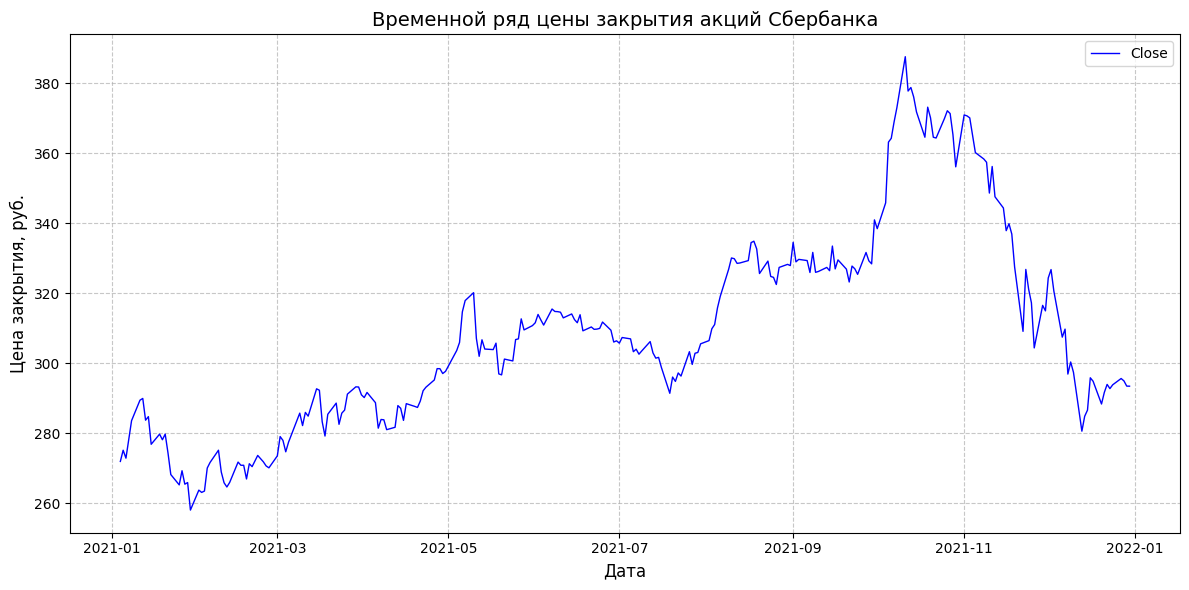

In [50]:
plot_close_series(stock_data.loc['2021-01-01':'2022-01-01'])

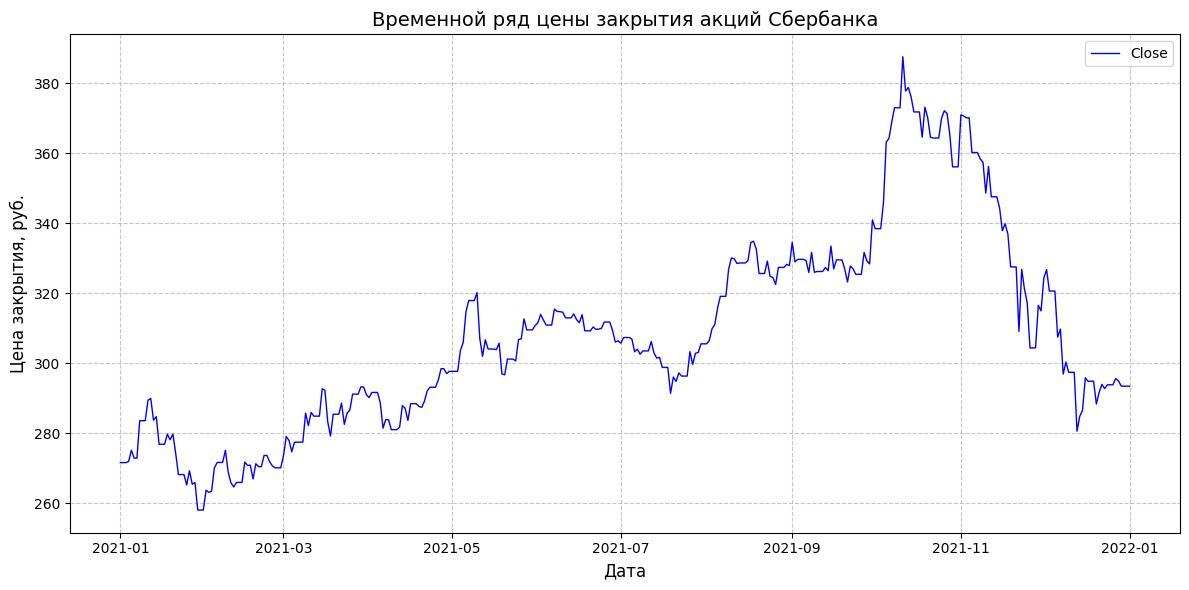

In [51]:
plot_close_series(forward_fill_stock_data.loc['2021-01-01':'2022-01-01'])

In [52]:
X, y = df_features.drop(TARGET_COLUMN, axis=1), df_features[TARGET_COLUMN]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [54]:
def variance_filter(X: pd.DataFrame, threshold: float = 0.01) -> pd.DataFrame:
    """
    Удаляет признаки с низкой дисперсией.
    
    Parameters
    ----------
    X : pd.DataFrame
        Исходные признаки.
    threshold : float, default=0.01
        Порог дисперсии (после стандартизации).
    
    Returns
    -------
    pd.DataFrame
        Отфильтрованный DataFrame.
    """
    logger.info(f"VarianceThreshold: порог = {threshold}")
    start = time.time()
    
    selector = VarianceThreshold(threshold=threshold)
    selector.fit(X)
    selected_features = X.columns[selector.get_support()]
    
    elapsed = time.time() - start
    logger.info(f"VarianceThreshold завершён за {elapsed:.2f} сек. "
                f"Признаков осталось: {len(selected_features)} из {X.shape[1]}")
    
    return X[selected_features]

In [ ]:
def permutation_importance_selection(
    X: pd.DataFrame,
    y: pd.Series,
    n_splits: int = 5,
    plot: bool = True,
    save_plot: bool = True
) -> pd.DataFrame:
    """
    Оценивает важность признаков с помощью перестановочной важности
    на кросс-валидации TimeSeriesSplit.
    
    Parameters
    ----------
    X : pd.DataFrame
        Признаки.
    y : pd.Series
        Целевая переменная.
    n_splits : int, default=5
        Число разбиений для TimeSeriesSplit.
    plot : bool, default=True
        Построить график важности.
    save_plot : bool, default=True
        Сохранить график в файл.
    
    Returns
    -------
    pd.DataFrame
        Таблица с признаками и их усреднённой важностью.
    """
    logger.info("Permutation Importance: старт")
    start = time.time()
    
    model = GradientBoostingRegressor(random_state=42)
    tscv = TimeSeriesSplit(n_splits=n_splits)
    
    importances_list = []
    
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X), 1):
        logger.debug(f"  Fold {fold}/{n_splits}")
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        model.fit(X_train, y_train)
        
        result = permutation_importance(
            model,
            X_test,
            y_test,
            n_repeats=10,
            random_state=42,
            scoring="neg_mean_absolute_percentage_error"
        )
        importances_list.append(result.importances_mean)
    
    importances_mean = np.mean(importances_list, axis=0)
    
    elapsed = time.time() - start
    logger.info(f"Permutation Importance завершён за {elapsed:.2f} сек.")
    
    importance_df = pd.DataFrame({
        "feature": X.columns,
        "importance": importances_mean
    }).sort_values(by="importance", ascending=False).reset_index(drop=True)
    
    return importance_df

In [56]:
def select_top_features(
    X: pd.DataFrame,
    importance_df: pd.DataFrame,
    top_n: int = 30
) -> pd.DataFrame:
    """
    Оставляет только top_n признаков с наибольшей важностью.
    """
    logger.info(f"Отбор топ-{top_n} признаков")
    selected_features = importance_df.head(top_n)["feature"].values
    logger.debug(f"Отобранные признаки: {list(selected_features)}")
    return X[selected_features]

In [ ]:
def rfecv_selection(
    X: pd.DataFrame,
    y: pd.Series,
    n_splits: int = 5,
    min_features: int = 10,
    plot: bool = True,
    save_plot: bool = True
):
    """
    Рекурсивное исключение признаков с кросс-валидацией (RFECV).
    
    Parameters
    ----------
    X, y : данные
    n_splits : число разбиений TimeSeriesSplit
    min_features : минимальное число признаков для отбора
    plot : построить график зависимости качества от числа признаков
    save_plot : сохранить график
    
    Returns
    -------
    selected_features : индексы отобранных признаков
    rfecv : обученный объект RFECV
    """
    logger.info("RFECV: старт")
    start = time.perf_counter()
    
    model = GradientBoostingRegressor(random_state=42)
    tscv = TimeSeriesSplit(n_splits=n_splits)
    
    rfecv = RFECV(
        estimator=model,
        step=1,
        cv=tscv,
        scoring="neg_mean_absolute_percentage_error",
        min_features_to_select=min_features,
        n_jobs=-1
    )
    
    rfecv.fit(X, y)
    
    elapsed = time.perf_counter() - start
    logger.info(f"RFECV завершён за {elapsed:.2f} сек.")
    logger.info(f"Оптимальное число признаков: {rfecv.n_features_}")
    
    return rfecv.support_, rfecv

In [59]:
def full_feature_selection_pipeline(
    df_features: pd.DataFrame,
    target_col: str = "Target",
    variance_threshold: float = 0.01,
    top_n: int = 30,
    n_splits: int = 5,
    min_features_rfecv: int = 10,
    plot_importance: bool = True,
    plot_rfecv: bool = True,
    save_plots: bool = True
) -> Tuple[np.ndarray, pd.DataFrame, RFECV, dict]:
    logger.info("=" * 60)
    logger.info("ЗАПУСК ПОЛНОГО ПАЙПЛАЙНА ОТБОРА ПРИЗНАКОВ")
    logger.info("=" * 60)
    
    X = df_features.drop(columns=[target_col])
    y = df_features[target_col]
    
    # Шаг 1
    X_variance = variance_filter(X, threshold=variance_threshold)
    after_variance = X_variance.columns.tolist()
    logger.info(f"После VarianceThreshold осталось: {len(after_variance)}")
    
    # Шаг 2: Permutation Importance
    importance_df = permutation_importance_selection(
        X_variance, y, n_splits=n_splits,
        plot=plot_importance, save_plot=save_plots
    )
    
    # Шаг 3: Отбор top-N
    X_top = select_top_features(X_variance, importance_df, top_n=top_n)
    after_topn = X_top.columns.tolist()
    logger.info(f"После отбора top-{top_n} осталось: {len(after_topn)}")
    
    # Шаг 4: RFECV
    final_mask, rfecv = rfecv_selection(
        X_top, y,
        n_splits=n_splits,
        min_features=min_features_rfecv,
        plot=plot_rfecv, save_plot=save_plots
    )
    
    final_features = X_top.columns[final_mask].tolist()
    logger.info(f"После RFECV финальных признаков: {len(final_features)}")
    
    stage_features = {
        'after_variance': after_variance,
        'after_topn': after_topn,
        'after_rfecv': final_features
    }
    
    return final_features, importance_df, rfecv, stage_features

In [64]:
def compare_windows_selection(
    df_features: pd.DataFrame,
    target_col: str = "Target",
    window_sizes: Tuple[int, ...] = (252, 504, 756),
    variance_threshold: float = 0.01,
    top_n: int = 30,
    n_splits: int = 5,
    min_features_rfecv: int = 20,
    plot: bool = True,
    save_plot: bool = False,
    selection_threshold: float = 0.5
):
    """
    Сравнивает отбор признаков на разных временных горизонтах (последние N дней).

    Для каждого размера окна из кортежа window_sizes берутся последние соответствующие
    строки данных, и на этом подмножестве запускается полный пайплайн отбора признаков.
    Для каждого этапа (VarianceThreshold, топ‑N, RFECV) собирается статистика:
    доля окон, в которых признак присутствовал после данного этапа.

    Возвращает словарь с тремя датафреймами:
        - 'variance' : частота прохождения VarianceThreshold
        - 'topn' : частота попадания в топ‑N
        - 'final' : частота попадания в финальный набор
        - 'selected_features' : список признаков с частотой в 'final' > selection_threshold
    """
    logger.info("=" * 60)
    logger.info("СРАВНЕНИЕ ОТБОРА ПРИЗНАКОВ НА РАЗНЫХ ВРЕМЕННЫХ ГОРИЗОНТАХ")
    logger.info(f"Размеры окон (дней): {window_sizes}")
    logger.info("=" * 60)

    df_features = df_features.sort_index(ascending=True)
    total_rows = len(df_features)

    all_features = df_features.drop(columns=[target_col]).columns.tolist()
    
    # Счётчики для каждого этапа
    count_variance = {feat: 0 for feat in all_features}
    count_topn = {feat: 0 for feat in all_features}
    count_final = {feat: 0 for feat in all_features}

    n_windows = 0
    accum = 0
    for size in window_sizes:
        if accum + size > total_rows:
            logger.warning(f"Окно {size} выходит за границы данных, пропускаем")
            continue
        window_df = df_features.iloc[accum:accum+size].copy()
        accum += size
        n_windows += 1
        logger.info(f"Окно {n_windows} размером {size}: {window_df.index[0]} - {window_df.index[-1]}")

        # Запускаем пайплайн, получаем stage_features
        _, _, _, stage = full_feature_selection_pipeline(
            df_features=window_df,
            target_col=target_col,
            variance_threshold=variance_threshold,
            top_n=top_n,
            n_splits=n_splits,
            min_features_rfecv=min_features_rfecv,
            plot_importance=False,
            plot_rfecv=False,
            save_plots=False
        )

        after_variance = set(stage['after_variance'])
        after_topn = set(stage['after_topn'])
        after_rfecv = set(stage['after_rfecv'])

        for feat in all_features:
            if feat in after_variance:
                count_variance[feat] += 1
            if feat in after_topn:
                count_topn[feat] += 1
            if feat in after_rfecv:
                count_final[feat] += 1

    if n_windows == 0:
        logger.error("Нет обработанных окон")
        return {}

    # Преобразуем в частоты
    freq_variance = pd.DataFrame({
        'feature': all_features,
        'frequency': [count_variance[f] / n_windows for f in all_features]
    }).sort_values('frequency', ascending=False).reset_index(drop=True)

    freq_topn = pd.DataFrame({
        'feature': all_features,
        'frequency': [count_topn[f] / n_windows for f in all_features]
    }).sort_values('frequency', ascending=False).reset_index(drop=True)

    freq_final = pd.DataFrame({
        'feature': all_features,
        'frequency': [count_final[f] / n_windows for f in all_features]
    }).sort_values('frequency', ascending=False).reset_index(drop=True)

    logger.info(f"Всего окон: {n_windows}")
    logger.info("Топ-10 признаков по частоте прохождения VarianceThreshold:")
    for i, row in freq_variance.head(10).iterrows():
        logger.info(f"  {row['feature']}: {row['frequency']:.2f}")

    if plot:
        fig, ax = plt.subplots(figsize=(10, 8))
        
        top_plot = min(30, len(freq_final))
        plot_df = freq_final.head(top_plot).sort_values('frequency', ascending=True)
        
        ax.barh(plot_df['feature'], plot_df['frequency'], color='skyblue')
        ax.set_xlabel('Доля окон')
        ax.set_title(f'Топ-{top_plot} признаков по частоте попадания в финальный набор')
        
        ax.axvline(x=0.5, color='red', linestyle='--', linewidth=1, label='Порог 0.5')
        ax.legend()
        
        ax.grid(axis='x', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()

    selected = freq_final[freq_final['frequency'] > selection_threshold]['feature'].tolist()
    logger.info(f"Отобрано признаков с частотой > {selection_threshold}: {len(selected)}")
    
    result = {
        'variance': freq_variance,
        'topn': freq_topn,
        'final': freq_final,
        'selected_features': selected
    }
    
    return result

2026-03-02 15:42:26,141 - INFO - ============================================================
2026-03-02 15:42:26,141 - INFO - СРАВНЕНИЕ ОТБОРА ПРИЗНАКОВ НА РАЗНЫХ ВРЕМЕННЫХ ГОРИЗОНТАХ
2026-03-02 15:42:26,142 - INFO - Размеры окон (дней): (332, 365, 365, 366, 365)
2026-03-02 15:42:26,143 - INFO - ============================================================
2026-03-02 15:42:26,150 - INFO - Окно 1 размером 332: 2020-10-05 00:00:00 - 2021-09-01 00:00:00
2026-03-02 15:42:26,150 - INFO - ============================================================
2026-03-02 15:42:26,152 - INFO - ЗАПУСК ПОЛНОГО ПАЙПЛАЙНА ОТБОРА ПРИЗНАКОВ
2026-03-02 15:42:26,153 - INFO - ============================================================
2026-03-02 15:42:26,155 - INFO - VarianceThreshold: порог = 0.01
2026-03-02 15:42:26,158 - INFO - VarianceThreshold завершён за 0.00 сек. Признаков осталось: 91 из 114
2026-03-02 15:42:26,160 - INFO - После VarianceThreshold осталось: 91
2026-03-02 15:42:26,162 - INFO - Permutation

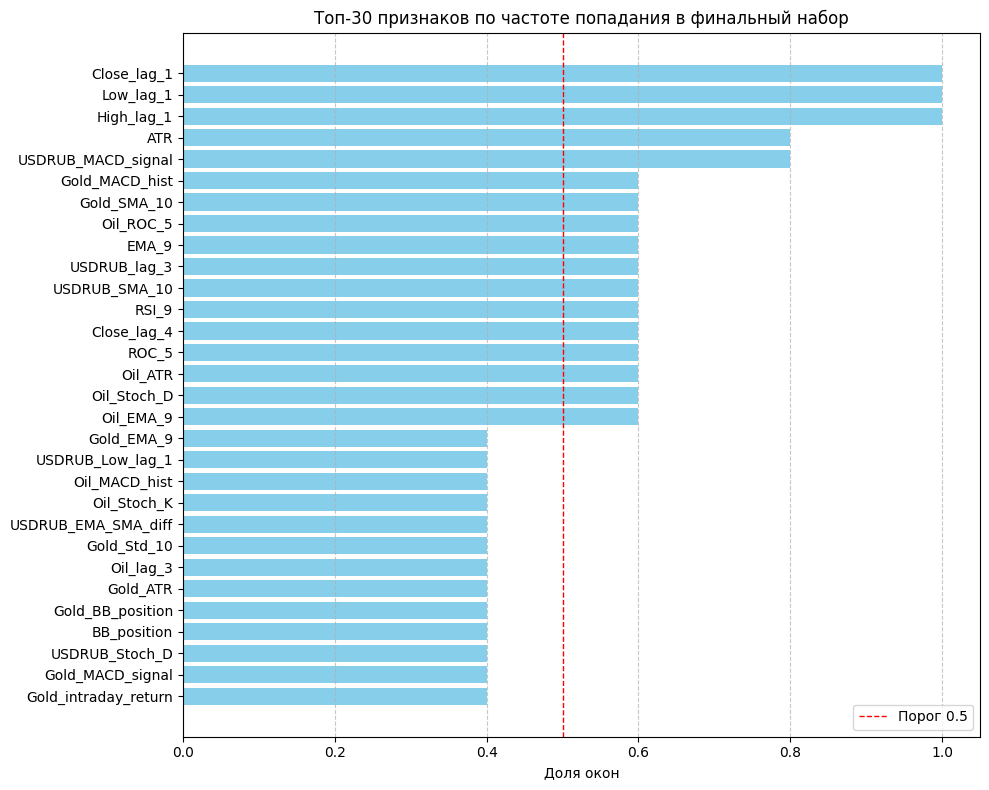

2026-03-02 15:44:02,472 - INFO - Отобрано признаков с частотой > 0.5: 17


In [65]:
result = compare_windows_selection(
    df_features=df_features,
    target_col='Close',
    window_sizes=(332, 365, 365, 366, 365),
    plot=True,
    save_plot=True
)

In [156]:
stable_features = result['selected_features']
print(f"Отобрано {len(stable_features)} стабильных признаков:")
print(stable_features)

Отобрано 17 стабильных признаков:
['Low_lag_1', 'High_lag_1', 'Close_lag_1', 'USDRUB_MACD_signal', 'ATR', 'Oil_Stoch_D', 'Oil_EMA_9', 'Oil_ATR', 'ROC_5', 'Close_lag_4', 'RSI_9', 'USDRUB_SMA_10', 'USDRUB_lag_3', 'Oil_ROC_5', 'Gold_SMA_10', 'EMA_9', 'Gold_MACD_hist']


In [157]:
X, y = df_features.drop(TARGET_COLUMN, axis=1), df_features[TARGET_COLUMN]
X = X[stable_features]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [161]:
def model_time_series_validation(
    model, 
    params) -> float:
    global X_train, y_train, X_test, y_test
    
    tscv = TimeSeriesSplit(n_splits=3)

    scores = []
    
    for train_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        if type(model) is xgb.XGBRegressor:
            model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
        else:
            model.fit(X_tr, y_tr)
        
        scores.append(mean_absolute_percentage_error(model.predict(X_val), y_val))

    if type(model) is xgb.XGBRegressor:
        model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
    else:
        model.fit(X_train, y_train)

    test_error = mean_absolute_percentage_error(model.predict(X_test), y_test)
    train_error = np.mean(scores)
    
    print(f'Train error: {train_error}; Test error: {test_error}')
    print(params)

    return train_error

In [162]:
def objective(trial: optuna.Trial) -> float:
    params = {
        'C': trial.suggest_float('C', 1e3, 1e4),
        'epsilon': trial.suggest_float('epsilon', 0.01, 5.0),
        'kernel': trial.suggest_categorical('kernel', ['rbf'])
    }

    model = Pipeline([
        ('scaler', MinMaxScaler()),
        ('svr', SVR(**params))
    ])
    
    return model_time_series_validation(model, params)

In [163]:
study = optuna.create_study(
    direction='minimize', 
    sampler=optuna.samplers.TPESampler(),
    pruner=optuna.pruners.HyperbandPruner()
)
study.optimize(objective, n_trials=50, show_progress_bar=True)

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.1853188453136837; Test error: 0.12739165341505612
{'C': 5420.573463678309, 'epsilon': 3.3309070589748595, 'kernel': 'rbf'}
Train error: 0.18394356368618095; Test error: 0.13651677940482604
{'C': 2097.999952812538, 'epsilon': 4.316399481424766, 'kernel': 'rbf'}
Train error: 0.21260808165029146; Test error: 0.12160764085178996
{'C': 4971.781580402492, 'epsilon': 1.296623149382232, 'kernel': 'rbf'}
Train error: 0.2206443781121982; Test error: 0.10251133687241884
{'C': 8730.214366642602, 'epsilon': 1.6233821836673066, 'kernel': 'rbf'}
Train error: 0.18964655000890485; Test error: 0.13024233070388835
{'C': 8408.002846683548, 'epsilon': 3.2742756500479264, 'kernel': 'rbf'}
Train error: 0.2545643304820427; Test error: 0.13467848229321805
{'C': 7975.550480778635, 'epsilon': 0.49888092934710976, 'kernel': 'rbf'}
Train error: 0.189146019659408; Test error: 0.14753415897580827
{'C': 8997.56467326534, 'epsilon': 3.7604871534202764, 'kernel': 'rbf'}
Train error: 0.203882369977976; Te

In [164]:
model = Pipeline([
    ('scaler', MinMaxScaler()),
    ('svr', SVR(**study.best_params))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(mean_absolute_percentage_error(y_pred, y_test))

0.1352475856018508


In [165]:
def test_plot(y_pred, y_test) -> None:
    df = pd.DataFrame({'Date': y_test.index, 'True_close': y_test.values, 'Pred_close': y_pred})

    plt.figure(figsize=(12, 6))
    sns.lineplot(data=df, x='Date', y='True_close', color='blue', label='Фактические значения (y_test)', linewidth=2)
    sns.lineplot(data=df, x='Date', y='Pred_close', color='red', marker='o', label='Предсказанные значения (y_pred)', linewidth=2)
    plt.title('Сравнение фактических и предсказанных значений', fontsize=14, fontweight='bold')
    plt.xlabel('Дата', fontsize=12)
    plt.ylabel('Значения', fontsize=12)
    plt.legend(fontsize=10)
    plt.xticks(rotation=45)
    
    plt.gcf().autofmt_xdate()
    
    plt.tight_layout()
    plt.show()

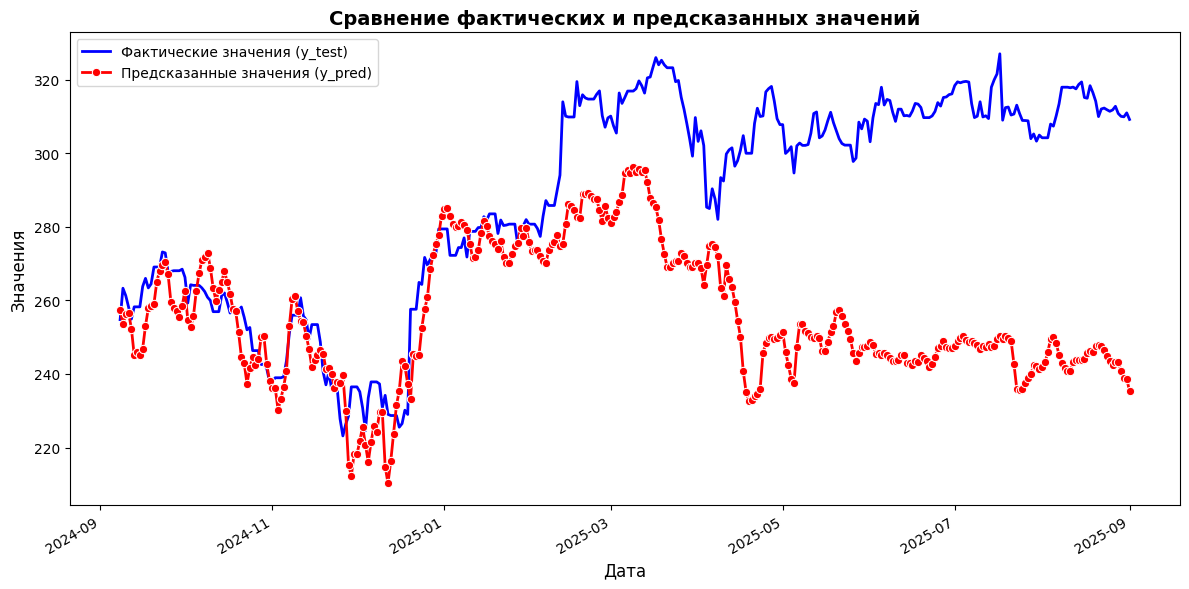

In [166]:
test_plot(y_pred, y_test)

In [168]:
def objective(trial: optuna.Trial) -> float:
    params = {
        'tree_method': trial.suggest_categorical('tree_method', ['exact']),
        'n_estimators': trial.suggest_int('n_estimators', 1500, 2000),
        'max_depth': trial.suggest_int('max_depth', 4, 8),
        'min_child_weight': trial.suggest_float('min_child_weight', 5.0, 15.0, log=True),
        'learning_rate': trial.suggest_categorical('learning_rate', [0.1]),
        'subsample': trial.suggest_float('subsample', 0.7, 0.9),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 0.9),
        'reg_lambda': trial.suggest_float('reg_lambda', 300, 500, log=True),
        'early_stopping_rounds': trial.suggest_categorical('early_stopping_rounds', [100]),
        'n_jobs': -1
    }

    model = xgb.XGBRegressor(**params)
    
    return model_time_series_validation(model, params)

In [169]:
study = optuna.create_study(
    direction='minimize', 
    sampler=optuna.samplers.TPESampler(),
    pruner=optuna.pruners.HyperbandPruner()
)
study.optimize(objective, n_trials=50, show_progress_bar=True)

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.10964604116638432; Test error: 0.010637863944721196
{'tree_method': 'exact', 'n_estimators': 1814, 'max_depth': 4, 'min_child_weight': 8.922715083760218, 'learning_rate': 0.1, 'subsample': 0.8473407239374788, 'colsample_bytree': 0.8450077759839889, 'reg_lambda': 437.4827969744444, 'early_stopping_rounds': 100, 'n_jobs': -1}
Train error: 0.10944350771897586; Test error: 0.011448505484658245
{'tree_method': 'exact', 'n_estimators': 1905, 'max_depth': 6, 'min_child_weight': 13.241558240121417, 'learning_rate': 0.1, 'subsample': 0.8075968941138235, 'colsample_bytree': 0.7850500362048298, 'reg_lambda': 408.9162045747648, 'early_stopping_rounds': 100, 'n_jobs': -1}
Train error: 0.1103175139236486; Test error: 0.010950567270784275
{'tree_method': 'exact', 'n_estimators': 1548, 'max_depth': 4, 'min_child_weight': 9.795443030755225, 'learning_rate': 0.1, 'subsample': 0.8002142096542387, 'colsample_bytree': 0.7802178004514488, 'reg_lambda': 469.1875117512476, 'early_stopping_round

In [170]:
model = xgb.XGBRegressor(**study.best_params)
model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_test, y_test)], verbose=False)
y_pred = model.predict(X_test)
print(mean_absolute_percentage_error(y_pred, y_test))

0.01146269241277367


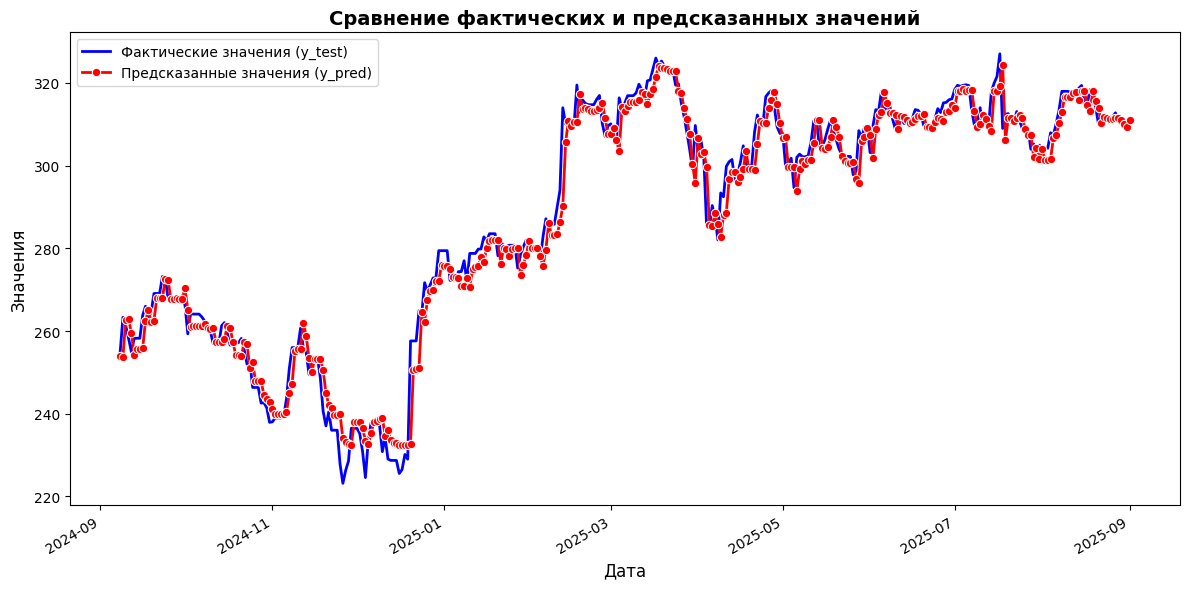

In [171]:
test_plot(y_pred, y_test)

In [174]:
def objective(trial: optuna.Trial) -> float:
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 500, 2000),
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'min_samples_split': trial.suggest_int('min_samples_split', 5, 8),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 4),
        'max_samples': trial.suggest_float('max_samples', 0.4, 0.9),
        'max_features': trial.suggest_categorical('max_features', ['sqrt']),
        'n_jobs': -1
    }

    model = RandomForestRegressor(**params)
    
    return model_time_series_validation(model, params)

In [175]:
study = optuna.create_study(
    direction='minimize', 
    sampler=optuna.samplers.TPESampler(),
    pruner=optuna.pruners.HyperbandPruner()
)
study.optimize(objective, n_trials=50, show_progress_bar=True)

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.10965196474354771; Test error: 0.012443875160615032
{'n_estimators': 1158, 'max_depth': 7, 'min_samples_split': 7, 'min_samples_leaf': 4, 'max_samples': 0.8590920619136552, 'max_features': 'sqrt', 'n_jobs': -1}
Train error: 0.11003412754709635; Test error: 0.012285047746282975
{'n_estimators': 1078, 'max_depth': 10, 'min_samples_split': 6, 'min_samples_leaf': 1, 'max_samples': 0.42043926897356076, 'max_features': 'sqrt', 'n_jobs': -1}
Train error: 0.10889101046485357; Test error: 0.012120196320970448
{'n_estimators': 850, 'max_depth': 9, 'min_samples_split': 7, 'min_samples_leaf': 2, 'max_samples': 0.5973481295457461, 'max_features': 'sqrt', 'n_jobs': -1}
Train error: 0.11111692738368607; Test error: 0.012237599653232574
{'n_estimators': 780, 'max_depth': 8, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_samples': 0.7399145480348563, 'max_features': 'sqrt', 'n_jobs': -1}
Train error: 0.10978627975351403; Test error: 0.012385952597461829
{'n_estimators': 614, 'max_de

In [176]:
model = RandomForestRegressor(**study.best_params)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(mean_absolute_percentage_error(y_pred, y_test))

0.011920711632156711


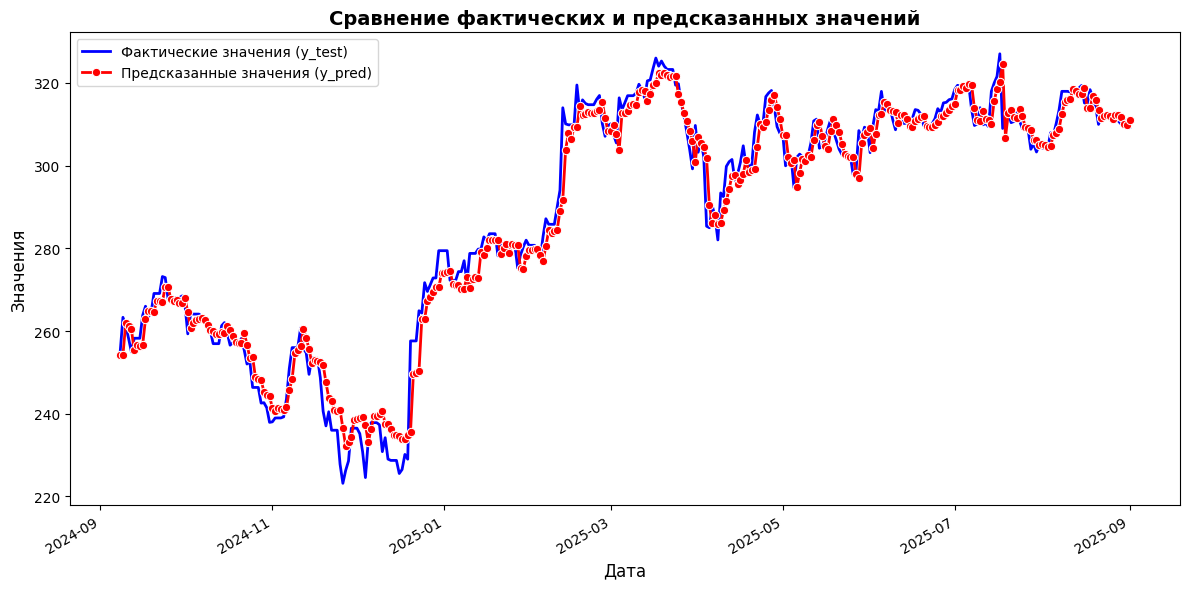

In [177]:
test_plot(y_pred, y_test)